# Imports iniciais

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from plotly import graph_objects as go
import seaborn as sns

# Leitura e informaçoes do arquivo

In [37]:
df_rest = pd.read_csv('data/rest_data_us.csv')

In [38]:
print(df_rest.info())
print()
display(df_rest.head())
print()
print(f"Linhas duplicadas: {df_rest.duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 9651 entries, 0 to 9650
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           9651 non-null   int64 
 1   object_name  9651 non-null   str   
 2   address      9651 non-null   str   
 3   chain        9648 non-null   object
 4   object_type  9651 non-null   str   
 5   number       9651 non-null   int64 
dtypes: int64(2), object(1), str(3)
memory usage: 452.5+ KB
None



,id,object_name,address,chain,object_type,number
0,11786,HABITAT COFFEE SHOP,3708 N EAGLE ROCK BLVD,False,Cafe,26
1,11787,REILLY'S,100 WORLD WAY # 120,False,Restaurant,9
2,11788,STREET CHURROS,6801 HOLLYWOOD BLVD # 253,False,Fast Food,20
3,11789,TRINITI ECHO PARK,1814 W SUNSET BLVD,False,Restaurant,22
4,11790,POLLEN,2100 ECHO PARK AVE,False,Restaurant,20



Linhas duplicadas: 0


In [39]:
df_rest['object_type'] = df_rest['object_type'].astype('category') # Define 'object_type' como categoria

In [40]:
# Verifica os nulos
print(df_rest[df_rest['chain'].isnull()])
print()
print(df_rest['chain'].value_counts())

         id              object_name               address chain object_type  \
7408  19194  TAQUERIA LOS 3 CARNALES  5000 E WHITTIER BLVD   NaN  Restaurant   
7523  19309     JAMMIN JIMMY'S PIZZA   1641 FIRESTONE BLVD   NaN       Pizza   
8648  20434    THE LEXINGTON THEATER          129 E 3RD ST   NaN  Restaurant   

      number  
7408      14  
7523       1  
8648      35  

chain
False    5972
True     3676
Name: count, dtype: int64


In [41]:
# Trata os nulos e verifica novamente
df_rest['chain'] = df_rest['chain'].fillna(False)
print(df_rest[df_rest['chain'].isnull()])

Empty DataFrame
Columns: [id, object_name, address, chain, object_type, number]
Index: []


Foi identificado 3 valores nulos na tabela, a decisão para eles foi substui-los com False, que já representea a maior parte do booleanos do dataframe.\
Como essas 3 linhas representão 0.03% da quantidade de linhas, o resultado dos gráficos não muito será afetado

# Análise dos dados

In [42]:
# Agrupa por contagem de cada tipo de estabelecimento
place_ratio = df_rest.groupby('object_type')['id'].count().reset_index()
place_ratio.columns = ['object_type', 'qty']

# Gera um gráfico de pizza
fig = go.Figure(data=[go.Pie(labels=place_ratio['object_type'], values=place_ratio['qty'])])
fig.update_layout(
    title={
        'text': 'Proporção de estabelecimento por tipo',
        'x': 0.5,
        'xanchor': 'center',
        'font': {
            'size': 18,
            'color': 'darkblue',
        }
    },)
fig.update_layout(width=600, height=400)
fig.show()

O gráfico mostra que pouco mais de 75% do estabelecimentos registrados na tabela são restaurantes. Logo atrás temos Fast Food (11%), Café (4,51%), e Pizza, Bar e Bakery, em torno de 3% cada

In [43]:
# Conta a quantidade de estabelecimentos por rede e não
chain_ratio = df_rest['chain'].value_counts()

# Gera um gráfico de barra
fig = px.bar(chain_ratio)
fig.update_layout(
    title={
        'text':'<b>Propoção de estabelecimento por rede ou não<b>',
        'x':0.5,
        'xanchor':'center',
        'font':{
            'size':13,
            'color': 'darkblue',
        }
    }
)

fig.update_layout(width=400, height=400,
                  xaxis_title="É rede?",
                  yaxis_title="Quantidade",
                  showlegend=False)
fig.show()

O gráfico mostra que aproximadamente 6 mil unidades não estão ligadas a uma rede, por outro lado, as quantidade de unidades que possuem uma rede gira em torno de ~3500 unidades

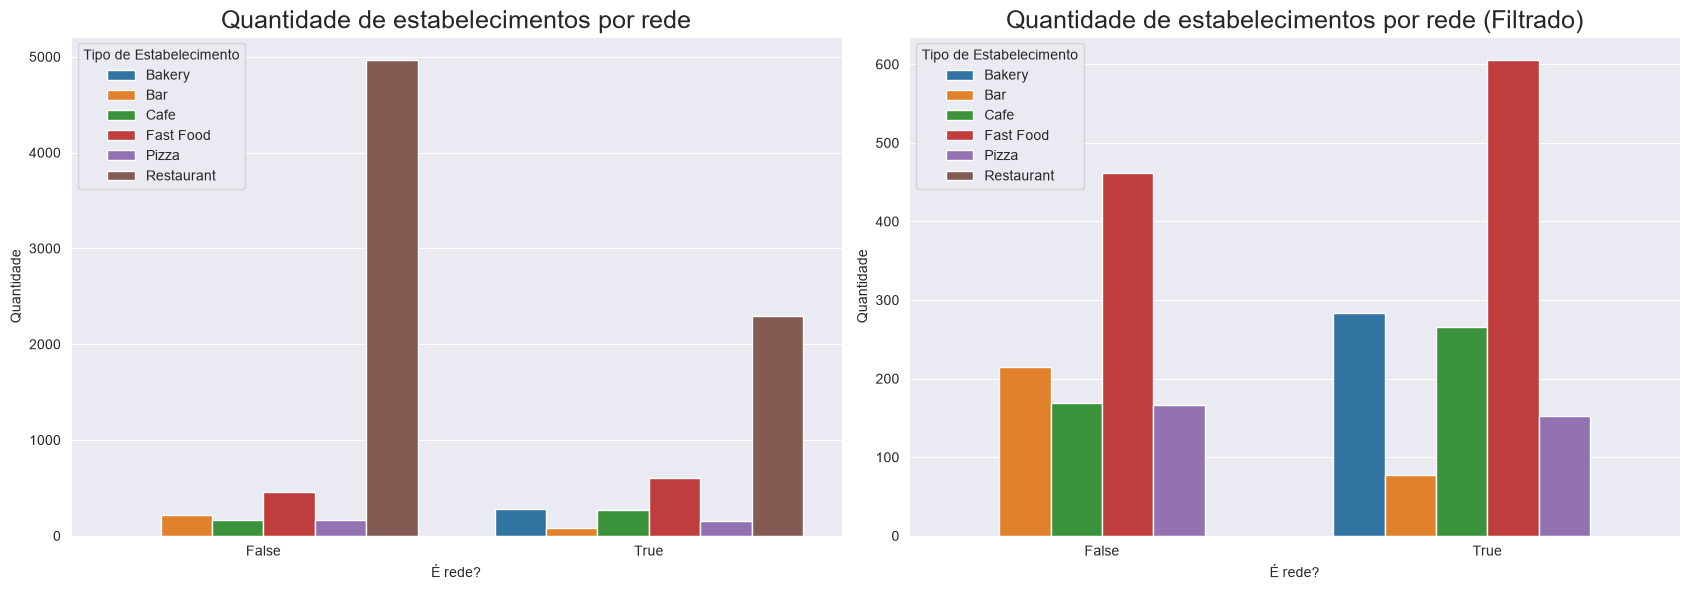

In [44]:
# Agrupa a contagem de estabelecimento por rede e não
chain_by_place = df_rest.groupby(['object_type', 'chain'])['id'].count().reset_index()
chain_by_place.columns = ['place_type', 'chain','quantity']
chain_by_place_filtered = chain_by_place[chain_by_place['place_type'] != 'Restaurant']

# Gera 2 gráficos de barra, um deles é filtrado para melhor visualização dos valores menores
sns.set_style(style='darkgrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17,6))
sns.barplot(
    data=chain_by_place,
    x='chain',
    y='quantity',
    hue='place_type',
    ax=ax1
)
ax1.set_title('Quantidade de estabelecimentos por rede', fontsize=18)
ax1.legend(title='Tipo de Estabelecimento', loc='upper left')
ax1.set_ylabel('Quantidade')
ax1.set_xlabel('É rede?')
sns.barplot(
    data=chain_by_place_filtered,
    x='chain',
    y='quantity',
    hue='place_type',
    ax=ax2
)
ax2.set_title('Quantidade de estabelecimentos por rede (Filtrado)', fontsize=18)
ax2.legend(title='Tipo de Estabelecimento')
ax2.set_ylabel('Quantidade')
ax2.set_xlabel('É rede?')
plt.tight_layout()
plt.show()

Os gráficos foram filtrados para melhor visualização, pois restaurantes representam pouco mais de 75% dos valores.\
O gráfico da esquerda mostra que aproximadamente 5 mil restaurantes não estão filiados a uma rede, logo, em torno ~2200 estão filiados.\
Já com os valores filtrados, podemos ver que Fast Food possui mais 600 unidades com redes filiadas, e por volta de ~550 não possuem.\
Em seguida, mais de 250 unidades de Cafés e Padarias são de redes, inclusive, não foram registradas padarias sem uma filiação.\
E o restante dos tipos, nenhum passa de 230 unidades, independente da filiação, Bar (~220), Café e Pizza (~180) não possuem rede filiada, e Bar (~90), Cafe (~160) estão com uma filiação.

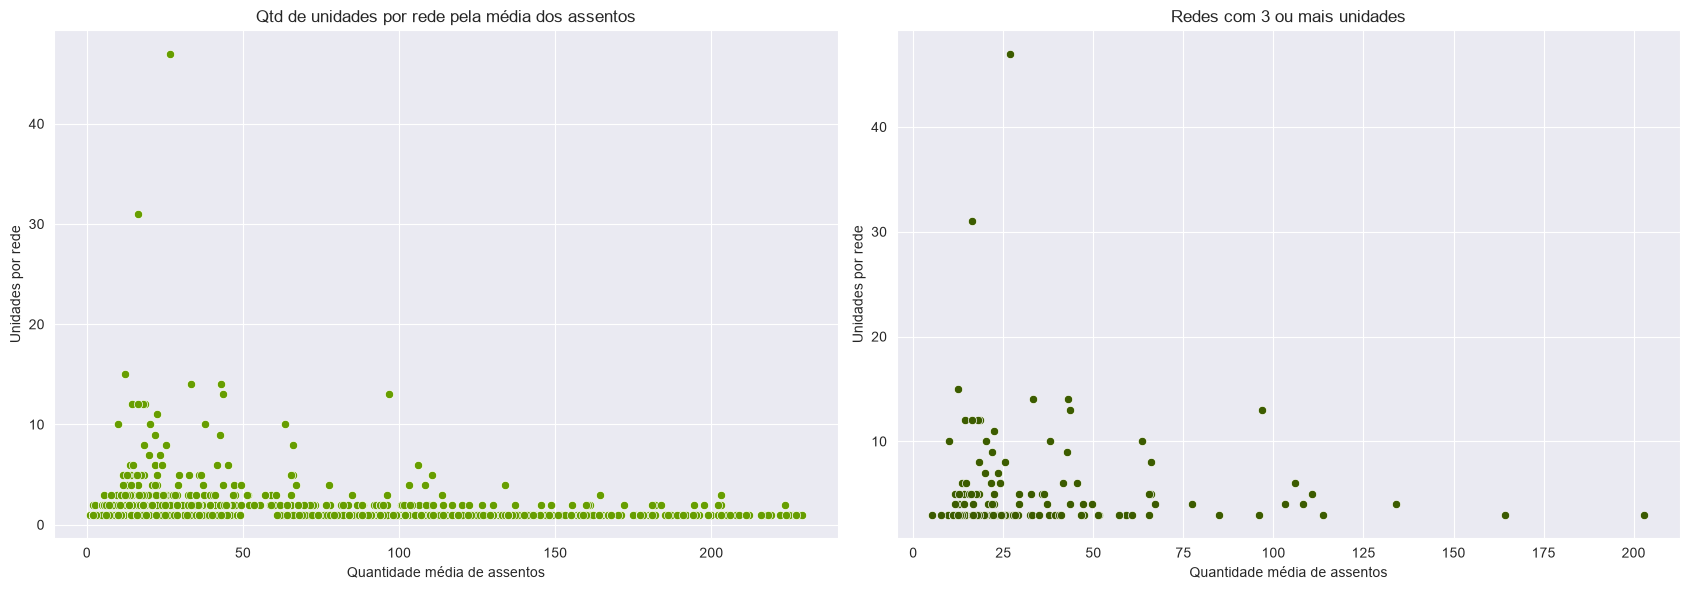

In [45]:
# Filtra e agrupa por contagem de unidade e quantidade média de assentos
seats_by_place_chainTrue = df_rest[df_rest['chain'] == True]
seats_by_place_chainTrue = seats_by_place_chainTrue.groupby('object_name').agg(
    unit_count=('object_type', 'count'),
    seats_mean=('number','mean')
).reset_index()

seats_by_place_chainTrue_3plus = seats_by_place_chainTrue[seats_by_place_chainTrue['unit_count'] >= 3]

# Gera um gráfico de dispersão
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17,6))
sns.scatterplot(
    data=seats_by_place_chainTrue,
    x='seats_mean',
    y='unit_count',
    color="#679E00",
    ax=ax1
)
ax1.set_ylabel('Unidades por rede')
ax1.set_xlabel('Quantidade média de assentos')
ax1.set_title('Qtd de unidades por rede pela média dos assentos')

sns.scatterplot(
    data=seats_by_place_chainTrue_3plus,
    x='seats_mean',
    y='unit_count',
    color="#3C5C00",
    ax=ax2
)
ax2.set_ylabel('Unidades por rede')
ax2.set_xlabel('Quantidade média de assentos')
ax2.set_title('Redes com 3 ou mais unidades')
plt.tight_layout()
plt.show()


In [46]:
print(f"Quantidade de assentos\n\nRedes com 2 unidades ou menos:\n{seats_by_place_chainTrue[seats_by_place_chainTrue['unit_count'] < 3]['seats_mean'].describe().loc[['mean', 'std', '25%', '75%', 'max']].round()}")
print()
print(f"Redes com 3 unidades ou mais:\n{seats_by_place_chainTrue_3plus['seats_mean'].describe().loc[['mean', 'std', '25%', '75%', 'max']].round()}")

Quantidade de assentos

Redes com 2 unidades ou menos:
mean     42.0
std      45.0
25%      14.0
75%      45.0
max     229.0
Name: seats_mean, dtype: float64

Redes com 3 unidades ou mais:
mean     34.0
std      31.0
25%      15.0
75%      41.0
max     203.0
Name: seats_mean, dtype: float64


A distrubuição de ambos os gráficos fica mais a esquerda (média baixa de assentos), caracterizando que as redes possuem muitos estabelecimentos, com pouca quantidade de assentos.\
As redes que se expandem, costumam ter uma média de assentos menor, em torno de 34, já as rede que tem apenas 1 ou 2 unidades, são tendênciadas a ter mais assentos, com uma média de 42.

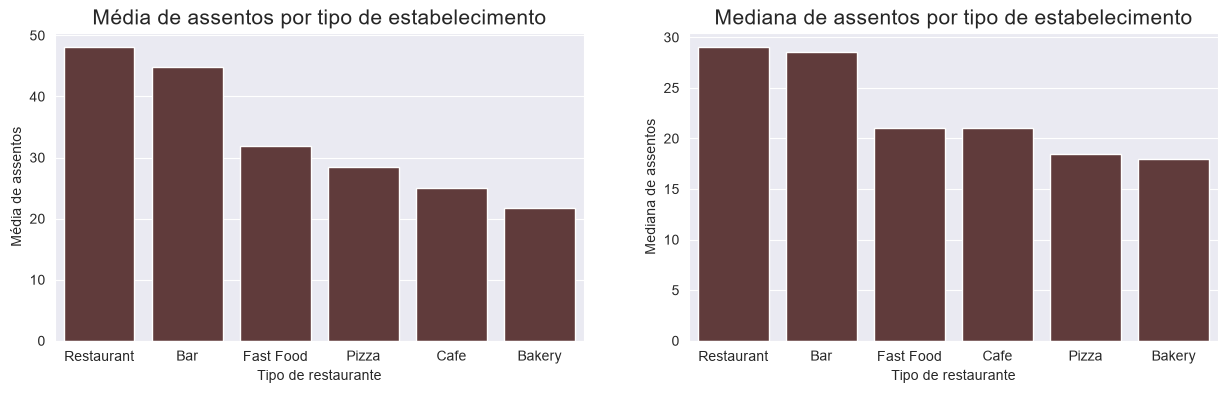

In [47]:
# Agrupa o tipo de estabelecimento pela média e mediana da quantidade de assentos
seats_by_type = df_rest.groupby('object_type').agg(
    seats_mean=('number', 'mean'),
    seats_median=('number', 'median')).reset_index().round(2)
seats_by_type = seats_by_type.sort_values(by='seats_mean', ascending=False)

# Gera os gráficos da média e mediana de assentos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15,4))
sns.barplot(
    data=seats_by_type,
    y='seats_mean',
    x='object_type',
    color="#663535",
    order=seats_by_type['object_type'].tolist(),
    ax=ax1
)
ax1.set_ylabel('Média de assentos')
ax1.set_xlabel('Tipo de restaurante')
ax1.set_title('Média de assentos por tipo de estabelecimento', fontsize=15)

seats_by_type = seats_by_type.sort_values(by='seats_median', ascending=False)
sns.barplot(
    data=seats_by_type,
    y='seats_median',
    x='object_type',
    color="#663535",
    order=seats_by_type['object_type'].tolist(),
    ax=ax2
)
ax2.set_ylabel('Mediana de assentos')
ax2.set_xlabel('Tipo de restaurante')
ax2.set_title('Mediana de assentos por tipo de estabelecimento', fontsize=15)
plt.show()

O gráfico mostra que os restaurantes possuem a maior média e assentos (~47), logo em seguida bares (~43) e por fim Fast Food, pizza, Cafe e Padarias firam abaixo de 32 assentos.\
Restaurantes possuem mais que o dobro de assentos que padarias, que estão na faixa dos 21 assentos por unidade.\
No gráfico a direita, a mediana nos mostra que Restaurantes e Bares possuem, na maior parte, quase a mesma quantidade da assentos (~27), o mesmo vale para Fast Food e Cafe (~21), e também entre Pizza e Padaria (~17).\
Não podemos esquecer que restaurantes compõem mais de 75% dos dados, por isso sua média se destaca entre as outras.

In [48]:
# Cria uma nova coluna com o nome das ruas 
df_rest['street'] = df_rest['address'].str.split(' ', n=1).str[1]
df_rest['street'] = df_rest['street'].str.replace(' #.*$| STE.*$| UNIT.*$| APT.*$| BLDG.*$| FL .*$', '',regex=True)
df_rest['street'] = df_rest['street'].str.replace('^[0-9]/[0-9] ', '',regex=True)

Foi detectado pequenos ruidos nos nomes das ruas, tais como STE, UNIT, APT, entre outros. A Remoção detalhada de cada um poderia comprometer o nome real da rua, gerando uma distorção nos resultados.\
Grande parte dos complementos foi removida, porém ainda temos algumas imprecisões relacionadas a rua de shopping / aeroportos.

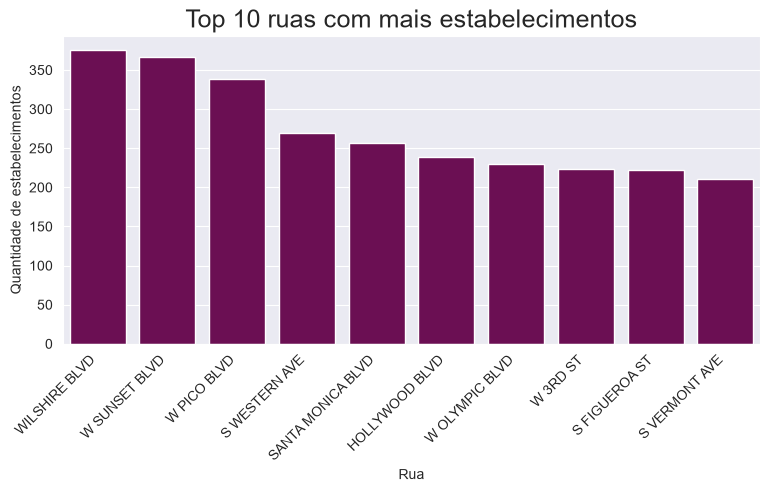

In [49]:
# Conta a quantidade de estabelecimentos por rua e separa o top 10
rest_by_street = df_rest.groupby('street').agg(rest_count=('id', 'count')).reset_index()
rest_by_street_top10 = rest_by_street.sort_values(by='rest_count', ascending=False).head(10)

# Gera uma gráfico
plt.figure(figsize=(9,4))
ax = sns.barplot(
    data=rest_by_street_top10,
    y='rest_count',
    x='street',
    color="#7A005B"
)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_title('Top 10 ruas com mais estabelecimentos', fontsize=18)
ax.set_ylabel('Quantidade de estabelecimentos')
ax.set_xlabel('Rua')
plt.show()

Podemos ver a diferença das 3 primeiras ruas, com valores acima dos 330, onde indica forte movimento comercial.\
A partir da 4ª rua, temos um degrau que desce para ~260 e segue em um leve queda até ~210 estabelecimentos disponiveis da última rua.\
O que leva a ter tantos estabelecimentos em tão poucas ruas? Como é dividida a concorrência entre eles?

In [50]:
streets_with_1_place = len(rest_by_street[rest_by_street['rest_count'] == 1])
print(f"Quantidade de ruas com apenas 1 estabelecimento: {streets_with_1_place}")

Quantidade de ruas com apenas 1 estabelecimento: 517


Temos 517 endereços que possuem apenas 1 estabelecimento, provavelmente são endereços de bairros periféricos onde não há muito movimento comercial, e prioriza-se prédio residenciais.

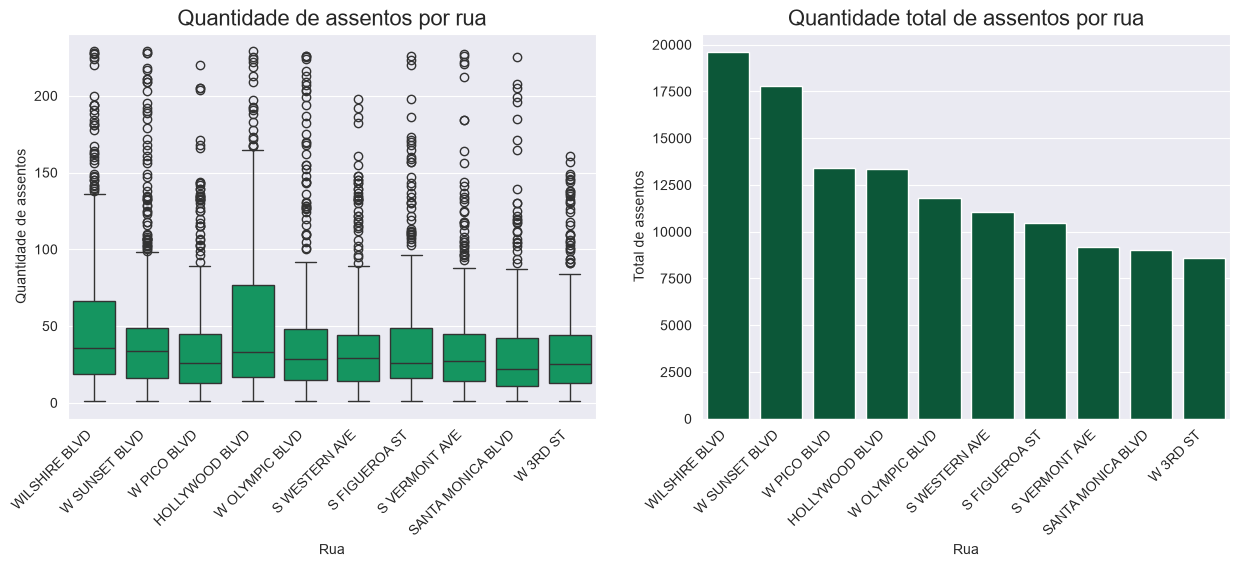

In [51]:
# Filtra o dataframe para conter apenas as ruas do top 10 e agrupa pela quantidade total de assentos
df_rest_top10_streets = df_rest[df_rest['street'].isin(rest_by_street_top10['street'])]
seats_by_place_top10 = df_rest_top10_streets.groupby('street').agg(
    total_seats=('number','sum')
).reset_index()
seats_by_place_top10 = seats_by_place_top10.sort_values(by='total_seats', ascending=False)

# Gera os gráficos de boxplot e barra da quantidade de assentos por rua
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15,5))
sns.boxplot(
    data=df_rest_top10_streets,
    y='number',
    x='street',
    color="#00AA63",
    order=seats_by_place_top10['street'].tolist(),
    ax=ax1
)
ax1.set_title('Quantidade de assentos por rua', fontsize=16)
ax1.set_ylabel('Quantidade de assentos')
ax1.set_xlabel('Rua')
plt.setp(ax1.get_xticklabels(), rotation=45, ha='right')
sns.barplot(
    data=seats_by_place_top10,
    y='total_seats',
    x='street',
    color="#00633A",
    ax=ax2
)
ax2.set_title('Quantidade total de assentos por rua', fontsize=16)
ax2.set_ylabel('Total de assentos')
ax2.set_xlabel('Rua')
plt.setp(ax2.get_xticklabels(), rotation=45, ha='right')
plt.show()

## Gráfico de caixa

O nosso gráfico de caixa, aponta que a mediana de assentos de todas as ruas fica em ~25 e ~35, que leva a interpretação de que os estabelecimentos tem o mesmo tamanho.\
Algumas caixas, como Wilshire e Hollywood, são maiores que as demais, estandos entre ~65 e ~75.\
Todas as ruas possuem uma cauda longa, com outliers que vão de 100 até ~230 assentos.

## Gráfico de barra

Wilshire e Sunset dominam com mais de 17 mil assentos totais cada rua, que inclusive, são as ruas com mais estabelecimentos.\
Seguindo, temos W Pico e Hollywood pareadas em ~13,4 mil assentos. Um fato interessante, é que no gráfico de estabelecimentos por rua, Hollywood estava em 6º lugar, com ~230 restaurantes, já no gráfico de total de assentos, ele sobe para 4º lugar, indicando que seus estabelecimentos são maiores.\
Por outro lado, Santa Monica que estava em 5º (estabelecimentos), cai para 9º (assentos totais), o que aponta que os estabelecimentos são menores, onde pode-se confirmar pela mediana do gráfico de caixa, que chega a ~25 

# Conclusão final

### Tipos
- O tipo Restaurante é o mais dominante, com 75% dos dados registrados, e também a maior média de assentos (~48), que é seguido de bares (~45). Porém na mediana, ambos ficam parecidos, em torno de ~27.
- As menores médias registradas foram de Fast Food, Pizza, Padarias e Cafés.
### Assentos
- O tamanho mediano dos estabelecimentos gira em torno de 25 a 30 assentos, com uma cauda longa que vai de 100 até ~230 assentos.
### Redes
- As redes que se expandem, tem uma média de 34 assentos, e as que não expandem, giram em torno de 42 assentos.
- Redes grandes, quase nao tem estabelecimentos com mais de 100 assentos.

Para o investimento em um bar, fast food ou café, os dados indicam menos espaço para os modelos. Para os bares, a maior parte não é de rede, e são os estabelecimentos que provavelmente chamará mais a atenção do pessoal que buscam um lugar para beber e reunir com os amigos, o que faz o lucro ficar divido entre você os outros. Já um estabelecimento de fast food ou café, você estaria concorrendo com grandes redes nas principais ruas da cidade, já que mais da metade dos estabelecimentos desses tipos são de rede.\
Uma possivel explicação que não é testada no estudo, em relação as pizzarias, é que elas também podem ser vendidas em fast food ou delivery, o que seria um risco a correr para o seu negócio. E uma padaria teria foco em vendas de pãe e massas, apenas para um público mais especifico.\
Por fim, o melhor modelo para investimento seria Restaurante com uma faixa de 25 a 30 assentos, buscando ruas onde não há tanta concorrência, preferencialmente as últimas do top 10, pois as primeiras concentram oferta. Com menos concorrência, e sem uma quantidade muito alta de assentos, isso venderia exclusividade para o cliente, que é o ponto chave para atenção de muitas pessoas.\
Todo o estudo foi feito com base em quantidade e tipo de estabelecimentos e assentos por tipo. As tabelas não possuem dados de receita ou séries temporais para que mostrem detalhes mais minuciosos em relação a qual projeto é o mais viavél. Isso inclui também o fato da demanda em relação a concorrência, apesar de termos muitos negócios filiados a rede, não temos dados financeiros para comprovar qual atrai mais clientes.\
Quanto a possibilidade de criar uma rede, não é o mais indicado, pois a maior parte das redes registradas tem apenas um negócio, ou seja, poucas redes se expandem, além da quantidade de assentos para o tipo orientado ser quase igual, ~28 para as filiadas e ~29 para as não filiadas, quase nenhuma rede em expansão tem média acima de 100 assentos. Os estabelecimentos grandes são típicos de redes pequenas, não das que se multiplicam.


Presentation: https://docs.google.com/presentation/d/1r6uw9P3scsJjP7RqmoFWN94Hmk6u_taWg51cMcXukUA/edit?usp=sharing